## Query a single EMIT RFL granule from a single patch

Patch 10_7_1 | 14 covering granule(s) | using EMIT_L2A_RFL_001_20220823T105327_2223507_009


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

reflectance dims/shape: ('downtrack', 'crosstrack', 'bands') (1280, 1242, 285)
In-patch pixels: 24130  (theoretical full 10 km @60m ~= 27,778)


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


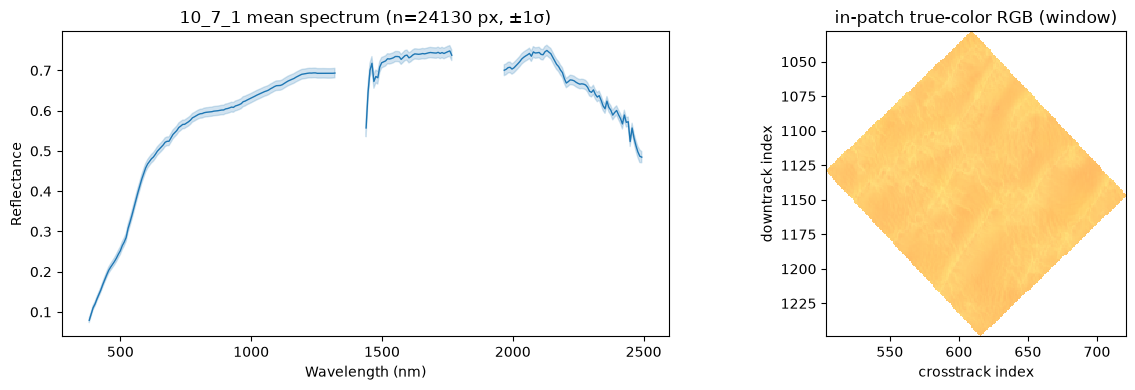

In [7]:
import warnings
import numpy as np
import geopandas as gpd
import shapely
import xarray as xr
import earthaccess
from scipy.spatial import KDTree
import logging
logging.getLogger("fsspec").setLevel(logging.WARNING)
import matplotlib.pyplot as plt

# ============================================================
# CONFIG  — all inputs defined locally / loaded from disk
# ============================================================
PICS_NAME        = "Libya_4"          # underscored, matches file naming
EXTRACT_PATCH_ID = "10_7_1"           # patch to extract; must exist in the gpkg
EXTRACT_PRODUCT  = "L2A_RFL"          # RFL only
DATE_START       = "2022-08-01"
DATE_END         = "2026-06-18"
FILL             = -9999.0

EMIT_PRODUCTS = {"L1B_RAD": "EMITL1BRAD", "L2A_RFL": "EMITL2ARFL"}

PATCHES_GPKG = (
    rf"C:\Users\huckr\Desktop\JPL\Data\ROIs\patches\patches_{PICS_NAME}_bnds.gpkg"
)

# Authenticate (standalone script needs its own login).
earthaccess.login(persist=True)

# Load patches from disk (replaces the upstream patches_gdf).
patches_gdf = gpd.read_file(PATCHES_GPKG)


# ============================================================
# FUNCTIONS
# ============================================================
def get_patch_4326(patches_gdf, patch_id):
    """Return the patch polygon reprojected to EPSG:4326 (tilted quad)."""
    sub = patches_gdf[patches_gdf["patch_id"] == patch_id]
    if sub.empty:
        raise ValueError(
            f"patch_id '{patch_id}' not in {PATCHES_GPKG}. "
            f"Available: {sorted(patches_gdf['patch_id'].tolist())[:10]}..."
        )
    return gpd.GeoSeries([sub.geometry.iloc[0]], crs=patches_gdf.crs).to_crs(4326).iloc[0]


def granule_footprint(umm):
    """Footprint polygon (EPSG:4326) from UMM-G GPolygons. Raises if absent."""
    try:
        gp = umm["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"]
        pts = gp[0]["Boundary"]["Points"]
    except (KeyError, IndexError) as exc:
        raise KeyError("Expected GPolygons not found in granule UMM.") from exc
    return shapely.geometry.Polygon([(p["Longitude"], p["Latitude"]) for p in pts])


def covering_granules(patch_4326, short_name, date_range):
    """Single live search over the patch bbox, filtered to granules whose
    footprint FULLY contains the patch. Returns a list of granule objects."""
    w, s, e, n = patch_4326.bounds
    results = earthaccess.search_data(
        short_name=short_name,
        bounding_box=(w, s, e, n),
        temporal=date_range,
        count=-1,
    )
    covering = []
    for g in results:
        fp = granule_footprint(g["umm"])
        if fp.contains(patch_4326):
            covering.append(g)
    return covering


def open_emit_l2a(granule):
    """Open an EMIT L2A RFL granule via earthaccess (authenticated streaming),
    reading groups by name. Returns dict: lon, lat, reflectance(lazy), wavelengths."""
    fobj = earthaccess.open([granule])[0]
    root = xr.open_dataset(fobj, engine="h5netcdf")
    refl = root["reflectance"]                       # ('downtrack','crosstrack','bands')
    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    wavelengths = np.asarray(bp["wavelengths"].data, dtype="float64")
    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    lon = np.asarray(loc["lon"].data, dtype="float64")
    lat = np.asarray(loc["lat"].data, dtype="float64")
    return {"root": root, "reflectance": refl,
            "wavelengths": wavelengths, "lon": lon, "lat": lat}


def patch_pixel_mask(patch_4326, lon, lat, fill=FILL):
    """Boolean (downtrack, crosstrack) mask of pixels inside the patch polygon.
    KDTree pre-filters to a disk around the patch centroid; shapely makes the
    exact point-in-polygon call on the candidates."""
    valid = (lon != fill) & (lat != fill) & np.isfinite(lon) & np.isfinite(lat)
    cx, cy = patch_4326.centroid.x, patch_4326.centroid.y
    w, s, e, n = patch_4326.bounds
    radius = 0.5 * np.hypot(e - w, n - s) * 1.10

    flat_idx = np.flatnonzero(valid)
    if flat_idx.size == 0:
        return np.zeros(lon.shape, dtype=bool)
    pts = np.column_stack([lon.ravel()[flat_idx], lat.ravel()[flat_idx]])

    tree = KDTree(pts)
    cand_local = tree.query_ball_point([cx, cy], r=radius)
    if not cand_local:
        return np.zeros(lon.shape, dtype=bool)

    cand_flat = flat_idx[np.asarray(cand_local)]
    inside = shapely.contains_xy(patch_4326,
                                 lon.ravel()[cand_flat],
                                 lat.ravel()[cand_flat])
    mask = np.zeros(lon.size, dtype=bool)
    mask[cand_flat[inside]] = True
    return mask.reshape(lon.shape)


def extract_patch(refl, mask, fill_values=(-9999.0, -0.01)):
    if not mask.any():
        return None, None, 0
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    block = refl[r0:r1, c0:c1, :].values
    submask = mask[r0:r1, c0:c1]
    pix = block[submask, :].astype("float64")
    pix[np.isclose(pix, -9999.0)] = np.nan
    pix[np.isclose(pix, -0.01, atol=1e-4)] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_spec = np.nanmean(pix, axis=0)
    return mean_spec, pix, pix.shape[0]


def nearest_band(wl, target_nm):
    return int(np.argmin(np.abs(wl - target_nm)))


def patch_rgb(refl, mask, wl, fill_values=(-9999.0, -0.01),
              rgb_nm=(650.0, 550.0, 450.0), vmin=0.0, vmax=0.45):
    """True-color RGB of in-patch pixels; shared stretch preserves color ratio."""
    if not mask.any():
        return None, None
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    submask = mask[r0:r1, c0:c1]
    bidx = [nearest_band(wl, t) for t in rgb_nm]
    block = refl[r0:r1, c0:c1, bidx].values.astype("float64")
    for fv in fill_values:
        block[np.isclose(block, fv, atol=1e-4)] = np.nan
    rgb = np.clip((block - vmin) / (vmax - vmin), 0, 1)
    alpha = submask.astype("float64")
    return np.dstack([rgb, alpha]), submask


# ============================================================
# DRIVER — one granule, validate the mechanic
# ============================================================
patch_4326 = get_patch_4326(patches_gdf, EXTRACT_PATCH_ID)

# Single live search -> granules fully covering the patch (objects, ready to stream).
covering = covering_granules(patch_4326, EMIT_PRODUCTS[EXTRACT_PRODUCT],
                             (DATE_START, DATE_END))
if not covering:
    raise ValueError(f"No fully-covering {EXTRACT_PRODUCT} granules for {EXTRACT_PATCH_ID}.")

granule = covering[0]
target_ur = granule["umm"].get("GranuleUR")
print(f"Patch {EXTRACT_PATCH_ID} | {len(covering)} covering granule(s) | using {target_ur}")

emit = open_emit_l2a(granule)
lon, lat = emit["lon"], emit["lat"]
refl, wl = emit["reflectance"], emit["wavelengths"]
print("reflectance dims/shape:", refl.dims, refl.shape)

mask = patch_pixel_mask(patch_4326, lon, lat)
mean_spec, pix_stack, n_pix = extract_patch(refl, mask)

patch_km = int(EXTRACT_PATCH_ID.split("_")[0])
theoretical = (patch_km * 1000 / 60) ** 2
print(f"In-patch pixels: {n_pix}  (theoretical full {patch_km} km @60m ~= {theoretical:,.0f})")

# ============================================================
# QUICK VALIDATION PLOTS
# ============================================================
if mean_spec is not None:
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4))

    sd = np.nanstd(pix_stack, axis=0)
    axL.plot(wl, mean_spec, lw=1, color="C0")
    axL.fill_between(wl, mean_spec - sd, mean_spec + sd, color="C0", alpha=0.2)
    axL.set_xlabel("Wavelength (nm)"); axL.set_ylabel("Reflectance")
    axL.set_title(f"{EXTRACT_PATCH_ID} mean spectrum (n={n_pix} px, ±1σ)")

    rgba, _ = patch_rgb(refl, mask, wl)
    rows, cols = np.where(mask)
    r0, r1, c0, c1 = rows.min(), rows.max()+1, cols.min(), cols.max()+1
    axR.imshow(rgba, interpolation="nearest", extent=(c0, c1, r1, r0))
    axR.set_xlabel("crosstrack index"); axR.set_ylabel("downtrack index")
    axR.set_title("in-patch true-color RGB (window)")
    plt.tight_layout(); plt.show()
else:
    print("No pixels fell inside the patch — check CRS/containment.")

In [10]:
import re

# --- helpers ---
BINARY_FLAGS = {"Cloud flag", "Cirrus flag", "Water flag", "Spacecraft Flag",
                "Dilated Cloud Flag", "Aggregate Flag"}

def open_emit_file_by_token(granule, token):
    """Return (root_dataset, file_object) for the file in `granule` whose URL
    contains `token` (e.g. 'MASK', 'OBS')."""
    fobjs = earthaccess.open([granule])
    fo = next(fo for fo in fobjs
              if token.upper() in str(getattr(fo, "path", fo)).upper())
    return xr.open_dataset(fo, engine="h5netcdf"), fo

def band_index(fo, group, band_var, label):
    """Index of `label` within a file's band-label array (read by name)."""
    bp = xr.open_dataset(fo, group=group, engine="h5netcdf")
    labels = [str(x) for x in bp[band_var].values]
    return labels.index(label)

# --- MASK: same acquisition as the RFL granule already opened ---
m_root, mask_fo = open_emit_file_by_token(granule, "MASK")
mask_cube = m_root["mask"]
mask_labels = [str(x) for x in
               xr.open_dataset(mask_fo, group="sensor_band_parameters",
                               engine="h5netcdf")["mask_bands"].values]

# --- OBS: matching L1B RAD granule by acquisition stamp ---
stamp = re.search(r"_(\d{8}T\d{6})_", granule["umm"]["GranuleUR"]).group(1)
w, s, e, n = patch_4326.bounds
l1b = [g for g in earthaccess.search_data(
           short_name="EMITL1BRAD", bounding_box=(w, s, e, n),
           temporal=(DATE_START, DATE_END), count=-1)
       if stamp in g["umm"].get("GranuleUR", "")]
if not l1b:
    raise RuntimeError(f"No matching L1B granule for stamp {stamp}")
o_root, obs_fo = open_emit_file_by_token(l1b[0], "OBS")
obs_cube = o_root["obs"]
sza_idx = band_index(obs_fo, "sensor_band_parameters", "observation_bands",
                     "To-sun zenith (0 to 90 degrees from zenith)")
vza_idx = band_index(obs_fo, "sensor_band_parameters", "observation_bands",
                     "To-sensor zenith (0 to 90 degrees from zenith)")

# --- window + per-band helpers (depend on `mask` from the extractor) ---
rows, cols = np.where(mask)
r0, r1 = rows.min(), rows.max() + 1
c0, c1 = cols.min(), cols.max() + 1
submask = mask[r0:r1, c0:c1]

def windowed_band(cube, bidx, fill=(-9999.0,)):
    """Stream one band over the patch window, NaN fills, keep only in-patch."""
    arr = cube[r0:r1, c0:c1, bidx].values.astype("float64")
    for fv in fill:
        arr[np.isclose(arr, fv)] = np.nan
    arr[~submask] = np.nan
    return arr

def stats(arr, binary=False):
    vals = arr[np.isfinite(arr)]
    if vals.size == 0:
        return {}
    if binary:
        return {"% flagged": 100.0 * np.mean(vals > 0), "n": vals.size}
    return {"mean": np.mean(vals), "std": np.std(vals),
            "min": np.min(vals), "max": np.max(vals)}

print("MASK + OBS opened; defined:",
      ["mask_cube", "mask_labels", "obs_cube", "sza_idx", "vza_idx",
       "windowed_band", "stats", "BINARY_FLAGS"])

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

MASK + OBS opened; defined: ['mask_cube', 'mask_labels', 'obs_cube', 'sza_idx', 'vza_idx', 'windowed_band', 'stats', 'BINARY_FLAGS']


## Visualizes patch/scene data quality

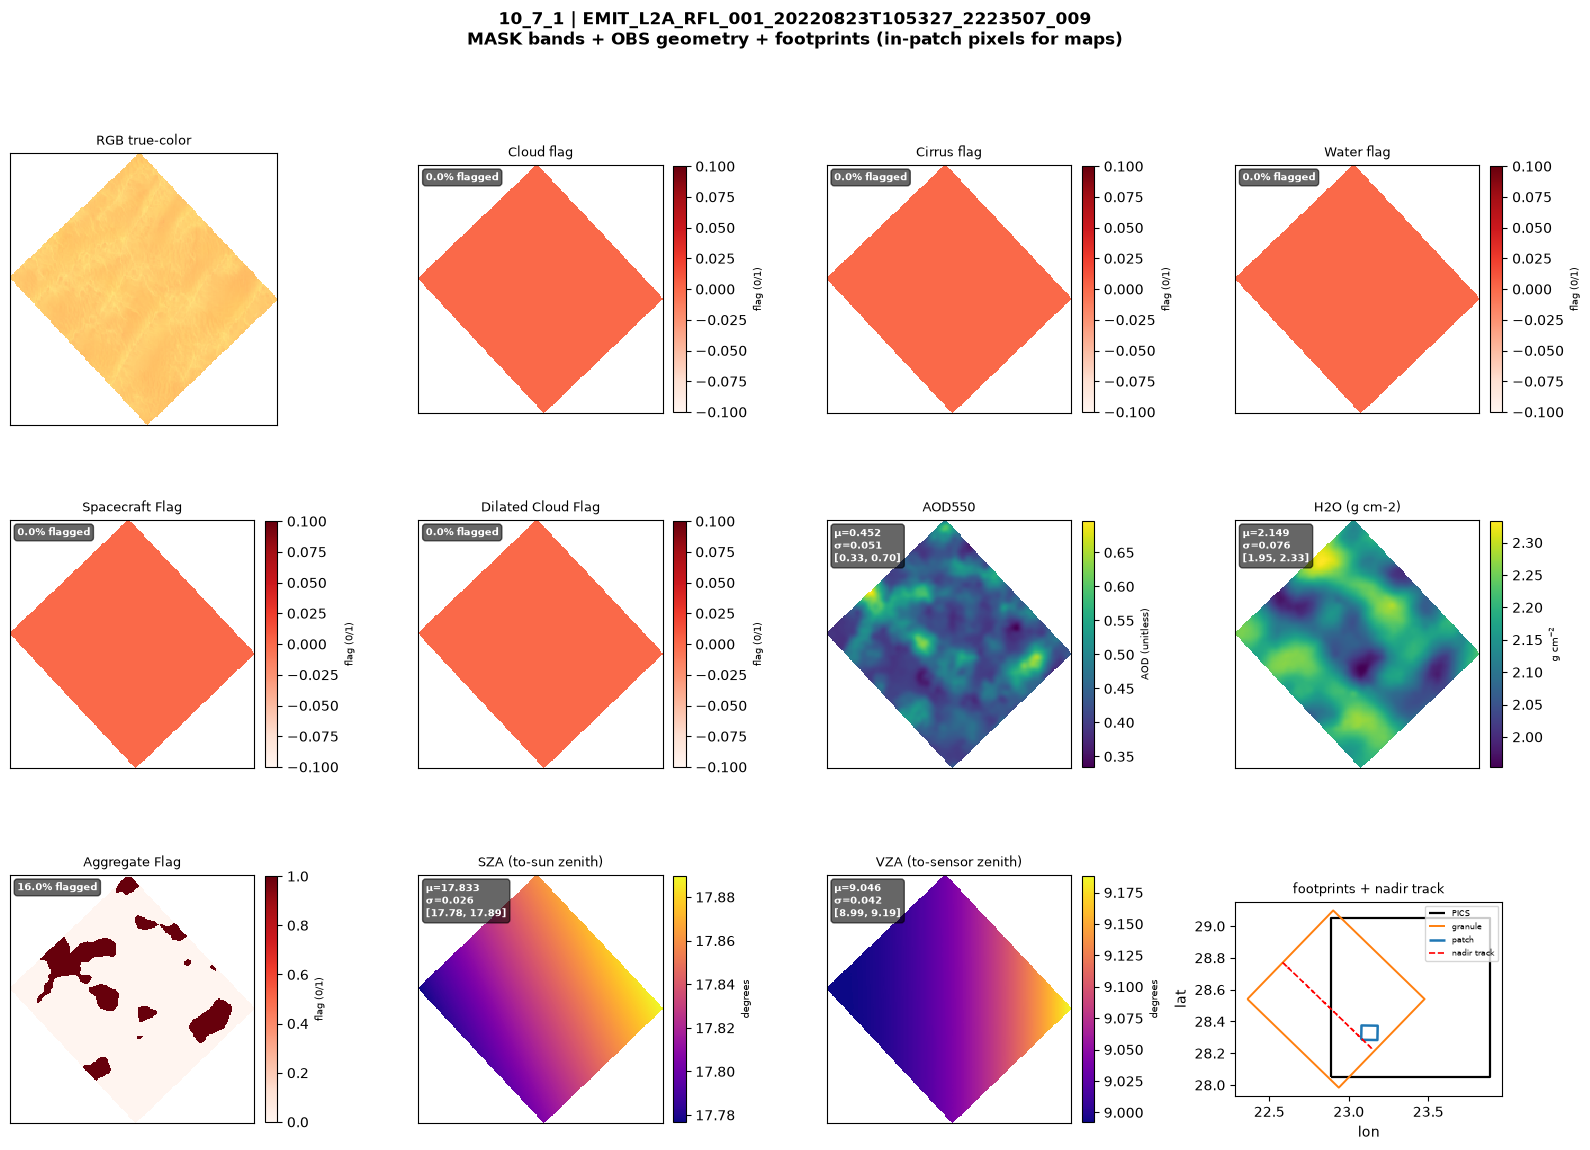

In [11]:
import geopandas as gpd
import shapely

# ============================================================
# Units per band (sourced from labels where possible)
# ============================================================
def band_units(label):
    """Unit string for a MASK/OBS band, inferred from its label."""
    if label in BINARY_FLAGS:
        return "flag (0/1)"
    if "g cm-2" in label or "H2O" in label:
        return "g cm$^{-2}$"
    if "AOD" in label:
        return "AOD (unitless)"
    if "zenith" in label or "azimuth" in label or "degrees" in label:
        return "degrees"
    return ""

# explicit units for the OBS-derived panels
SZA_UNITS = "degrees"
VZA_UNITS = "degrees"

# ============================================================
# Nadir track from OBS VZA: per downtrack row, the crosstrack pixel
# with the smallest to-sensor zenith (closest to directly below sensor).
# Computed over the FULL scene (not just the patch window) so the track
# spans the whole footprint.
# ============================================================
vza_full = obs_cube[:, :, vza_idx].values.astype("float64")   # (downtrack, crosstrack)
vza_full[np.isclose(vza_full, -9999.0)] = np.nan

nadir_lon, nadir_lat = [], []
for dr in range(vza_full.shape[0]):
    rowvals = vza_full[dr, :]
    if np.all(np.isnan(rowvals)):
        continue
    ct = np.nanargmin(rowvals)                 # crosstrack index of min VZA in this row
    nadir_lon.append(lon[dr, ct])              # lon/lat already loaded (full scene)
    nadir_lat.append(lat[dr, ct])
nadir_lon = np.array(nadir_lon)
nadir_lat = np.array(nadir_lat)

# ============================================================
# Footprints in EPSG:4326
# ============================================================
# granule footprint from the UMM GPolygon
gp = granule["umm"]["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"]
gran_poly = shapely.geometry.Polygon(
    [(p["Longitude"], p["Latitude"]) for p in gp[0]["Boundary"]["Points"]])

# PICS boundary (load from the PICS gpkg, reproject to 4326)
PICS_GPKG = r"C:\Users\huckr\Desktop\JPL\Data\ROIs\northafrican_pics.gpkg"
pics_gdf = gpd.read_file(PICS_GPKG)
pics_name_spaced = PICS_NAME.replace("_", " ")
pics_poly = gpd.GeoSeries(
    [pics_gdf[pics_gdf["site_name"] == pics_name_spaced].geometry.iloc[0]],
    crs=pics_gdf.crs).to_crs(4326).iloc[0]

# patch already in 4326 (patch_4326)

# ============================================================
# Plot grid: RGB, 8 MASK bands, SZA, VZA, + footprint panel
# ============================================================
items = []
rgba, _ = patch_rgb(refl, mask, wl)
items.append(("RGB true-color", rgba, None, None, None))
for i, lbl in enumerate(mask_labels):
    is_bin = lbl in BINARY_FLAGS
    items.append((lbl, windowed_band(mask_cube, i), is_bin,
                  "Reds" if is_bin else "viridis", band_units(lbl)))
items.append(("SZA (to-sun zenith)", windowed_band(obs_cube, sza_idx),
              False, "plasma", SZA_UNITS))
items.append(("VZA (to-sensor zenith)", windowed_band(obs_cube, vza_idx),
              False, "plasma", VZA_UNITS))
items.append(("FOOTPRINTS", None, None, None, None))   # special last panel

n = len(items)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
axes = axes.ravel()

for ax, item in zip(axes, items):
    title = item[0]

    if title == "RGB true-color":
        ax.imshow(item[1], interpolation="nearest")
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])

    elif title == "FOOTPRINTS":
        # PICS, granule, patch, nadir track — all in lon/lat
        gpd.GeoSeries([pics_poly], crs=4326).boundary.plot(
            ax=ax, color="black", lw=1.6, label="PICS")
        gpd.GeoSeries([gran_poly], crs=4326).boundary.plot(
            ax=ax, color="C1", lw=1.4, label="granule")
        gpd.GeoSeries([patch_4326], crs=4326).boundary.plot(
            ax=ax, color="C0", lw=1.8, label="patch")
        ax.plot(nadir_lon, nadir_lat, color="red", lw=1.2, ls="--", label="nadir track")
        ax.set_title("footprints + nadir track", fontsize=9)
        ax.set_xlabel("lon"); ax.set_ylabel("lat")
        ax.legend(fontsize=6, loc="upper right")
        ax.set_aspect("equal")

    else:
        _, arr, is_bin, cmap, units = item
        im = ax.imshow(arr, cmap=cmap, interpolation="nearest")
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(units, fontsize=7)
        st = stats(arr, binary=is_bin)
        if is_bin:
            txt = f"{st.get('% flagged', 0):.1f}% flagged"
        else:
            txt = (f"μ={st.get('mean', np.nan):.3f}\n"
                   f"σ={st.get('std', np.nan):.3f}\n"
                   f"[{st.get('min', np.nan):.2f}, {st.get('max', np.nan):.2f}]")
        ax.set_title(title, fontsize=9)
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, fontsize=7.5,
                va="top", ha="left", color="white", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.6))
        ax.set_xticks([]); ax.set_yticks([])

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(f"{EXTRACT_PATCH_ID} | {granule['umm']['GranuleUR']}\n"
             f"MASK bands + OBS geometry + footprints (in-patch pixels for maps)",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Simple diagnostic to find AOD threshold for aggregate flag

In [12]:
aod = windowed_band(mask_cube, mask_labels.index("AOD550"))
agg = windowed_band(mask_cube, mask_labels.index("Aggregate Flag"))
flagged = agg > 0
unflag = (~flagged) & np.isfinite(aod)

print(f"Flagged AOD:   min={np.nanmin(aod[flagged]):.3f}  "
      f"max={np.nanmax(aod[flagged]):.3f}  median={np.nanmedian(aod[flagged]):.3f}")
print(f"Unflagged AOD: min={np.nanmin(aod[unflag]):.3f}  "
      f"max={np.nanmax(aod[unflag]):.3f}  median={np.nanmedian(aod[unflag]):.3f}")
# the overlap zone is the tell:
print(f"\nHighest unflagged AOD: {np.nanmax(aod[unflag]):.3f}")
print(f"Lowest flagged AOD:    {np.nanmin(aod[flagged]):.3f}")

Flagged AOD:   min=0.500  max=0.696  median=0.532
Unflagged AOD: min=0.335  max=0.500  median=0.431

Highest unflagged AOD: 0.500
Lowest flagged AOD:    0.500


## Compare mean reflectance specta of earthaccess and AppEEARS products from 08/23/2022 at patch Libya 4 10_7_1

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\spectral\io\envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)
C:\Users\huckr\AppData\Local\Temp\ipykernel_96740\2461051183.py:42: RuntimeWarning: Mean of empty slice
  envi_mean = np.nanmean(flat, axis=0)


ENVI clip: 31652 valid pixels, 285 bands

Mean |difference|: 0.00001
Max  |difference|: 0.00002
Mean difference (bias): 0.00000


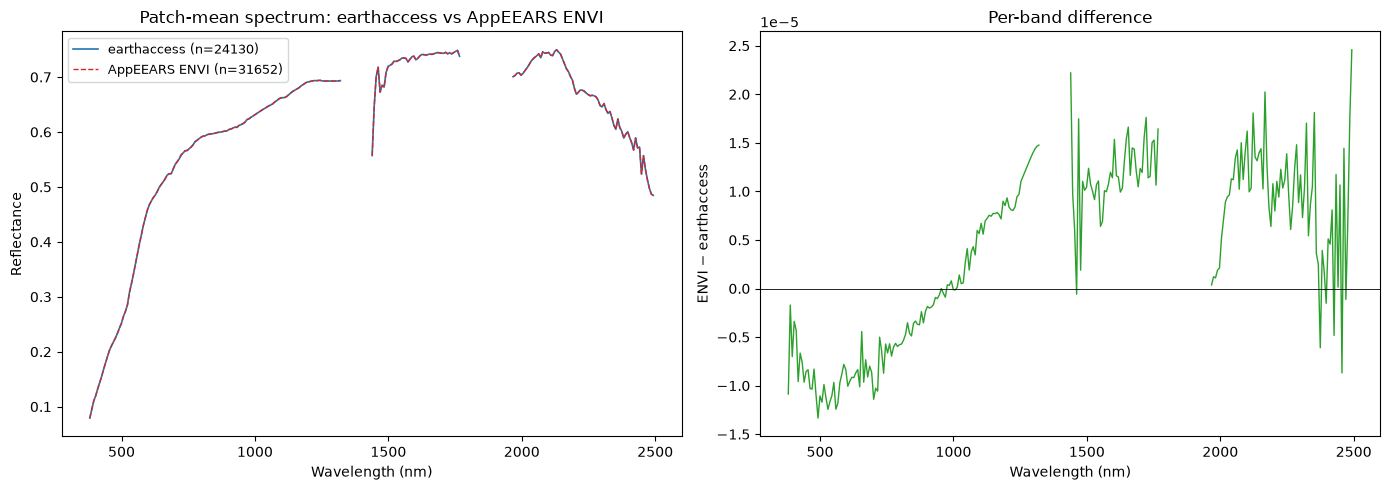

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from spectral.io import envi

# ============================================================
# CONFIG — point to the AppEEARS ENVI reflectance pair
# ============================================================
ENVI_DIR = r"C:\Users\huckr\Desktop\JPL\Data\AppEEARS\Libya4_10_7_1_08232022\ENVI_Format"
RFL_HDR = ENVI_DIR + r"\EMIT_L2A_RFL_001_20220823T105327_2223507_009_ortho_subset_aid0000_reflectance.hdr"

FILL_VALUES = (-9999.0, -0.01)

# ============================================================
# Read the ENVI reflectance cube + wavelengths from the header
# ============================================================
img = envi.open(RFL_HDR)           # reads .hdr; binary file (same name, no .hdr) auto-found
cube = img.load()                  # (rows, cols, bands) ortho grid
arr = np.asarray(cube, dtype="float64")

# wavelengths from the ENVI header metadata
md = img.metadata
if "wavelength" in md:
    wl_envi = np.array([float(x) for x in md["wavelength"]])
else:
    wl_envi = None
    print("No 'wavelength' field in ENVI header; will compare by band index.")

# ENVI may carry its own data-ignore value; respect it too
hdr_fill = md.get("data ignore value", None)
fills = list(FILL_VALUES) + ([float(hdr_fill)] if hdr_fill is not None else [])

# ============================================================
# Patch-mean spectrum from the ENVI clip (all valid pixels)
# ============================================================
flat = arr.reshape(-1, arr.shape[-1])        # (npix, bands)
for fv in fills:
    flat[np.isclose(flat, fv, atol=1e-4)] = np.nan
# drop pixels that are entirely fill (outside the ortho clip footprint)
all_nan = np.all(np.isnan(flat), axis=1)
flat = flat[~all_nan]
with np.errstate(all="ignore"):
    envi_mean = np.nanmean(flat, axis=0)
n_envi = flat.shape[0]
print(f"ENVI clip: {n_envi} valid pixels, {arr.shape[-1]} bands")

# ============================================================
# Compare to the earthaccess patch-mean (`mean_spec`, `wl` in scope)
# ============================================================
# Align by wavelength if available (ENVI wl may be in nm or µm — normalize)
if wl_envi is not None:
    # AppEEARS sometimes stores wavelength in micrometers; convert to nm if so
    if np.nanmax(wl_envi) < 100:        # looks like µm
        wl_envi_nm = wl_envi * 1000.0
    else:
        wl_envi_nm = wl_envi
    x_envi, x_ea = wl_envi_nm, wl
    xlabel = "Wavelength (nm)"
else:
    x_envi, x_ea = np.arange(envi_mean.size), np.arange(mean_spec.size)
    xlabel = "Band index"

# ============================================================
# Plot: overlay + difference
# ============================================================
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5))

axL.plot(x_ea, mean_spec, lw=1.2, color="C0", label=f"earthaccess (n={n_pix})")
axL.plot(x_envi, envi_mean, lw=1.0, color="C3", ls="--",
         label=f"AppEEARS ENVI (n={n_envi})")
axL.set_xlabel(xlabel); axL.set_ylabel("Reflectance")
axL.set_title("Patch-mean spectrum: earthaccess vs AppEEARS ENVI")
axL.legend(fontsize=9)

# difference (only valid if band grids match in length)
if envi_mean.size == mean_spec.size:
    diff = envi_mean - mean_spec
    axR.plot(x_ea, diff, lw=1, color="C2")
    axR.axhline(0, color="k", lw=0.6)
    axR.set_xlabel(xlabel); axR.set_ylabel("ENVI − earthaccess")
    axR.set_title("Per-band difference")
    valid = np.isfinite(diff)
    print(f"\nMean |difference|: {np.nanmean(np.abs(diff)):.5f}")
    print(f"Max  |difference|: {np.nanmax(np.abs(diff[valid])):.5f}")
    print(f"Mean difference (bias): {np.nanmean(diff):.5f}")
else:
    axR.text(0.5, 0.5, f"band count differs\nENVI={envi_mean.size}, EA={mean_spec.size}",
             ha="center", va="center", transform=axR.transAxes)
    print(f"\nBand counts differ: ENVI={envi_mean.size}, earthaccess={mean_spec.size}")

plt.tight_layout(); plt.show()

## Compare mean reflectance specta of earthaccess and AppEEARS products from 06/14/2026 at patch Libya 4 10_7_1

Acquisition stamp from ENVI file: 20260614T120829
earthaccess granule: EMIT_L2A_RFL_001_20260614T120829_2616508_018


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

earthaccess patch-mean: n=24193 pixels


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\spectral\io\envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


AppEEARS ENVI patch-mean: n=31652 pixels, 285 bands

Mean |difference|: 0.00000
Max  |difference|: 0.00000
Mean bias (ENVI − EA): 0.00000


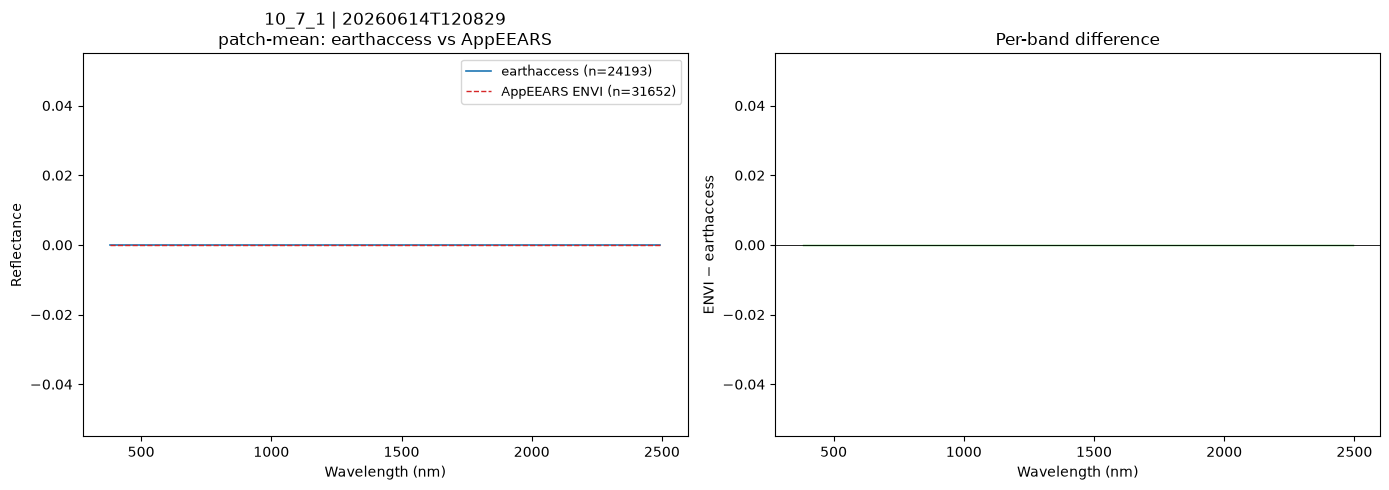

In [14]:
import warnings
import re
import numpy as np
import geopandas as gpd
import shapely
import xarray as xr
import earthaccess
from scipy.spatial import KDTree
from spectral.io import envi
import logging
logging.getLogger("fsspec").setLevel(logging.WARNING)
import matplotlib.pyplot as plt

# ============================================================
# CONFIG — set the ENVI .hdr path; everything else is derived
# ============================================================
RFL_HDR = (
    r"C:\Users\huckr\Desktop\JPL\Data\AppEEARS\Libya4_10_7_1_06142026"
    r"\ENVI_Format\EMIT_L2A_RFL_001_20260614T120829_2616508_018"
    r"_ortho_subset_aid0000_reflectance.hdr"
)
PICS_NAME        = "Libya_4"
EXTRACT_PATCH_ID = "10_7_1"
DATE_START       = "2022-08-01"
DATE_END         = "2026-06-18"
FILL_VALUES      = (-9999.0, -0.01)
FILL             = -9999.0
EMIT_PRODUCTS    = {"L1B_RAD": "EMITL1BRAD", "L2A_RFL": "EMITL2ARFL"}
PATCHES_GPKG = rf"C:\Users\huckr\Desktop\JPL\Data\ROIs\patches\patches_{PICS_NAME}_bnds.gpkg"

# acquisition stamp parsed straight from the ENVI filename
STAMP = re.search(r"_(\d{8}T\d{6})_", RFL_HDR).group(1)
print(f"Acquisition stamp from ENVI file: {STAMP}")

earthaccess.login(persist=True)
patches_gdf = gpd.read_file(PATCHES_GPKG)


# ============================================================
# FUNCTIONS (earthaccess side)
# ============================================================
def get_patch_4326(patches_gdf, patch_id):
    sub = patches_gdf[patches_gdf["patch_id"] == patch_id]
    if sub.empty:
        raise ValueError(f"patch_id '{patch_id}' not in {PATCHES_GPKG}.")
    return gpd.GeoSeries([sub.geometry.iloc[0]], crs=patches_gdf.crs).to_crs(4326).iloc[0]


def granule_footprint(umm):
    gp = umm["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"]
    pts = gp[0]["Boundary"]["Points"]
    return shapely.geometry.Polygon([(p["Longitude"], p["Latitude"]) for p in pts])


def covering_granules(patch_4326, short_name, date_range):
    w, s, e, n = patch_4326.bounds
    results = earthaccess.search_data(short_name=short_name, bounding_box=(w, s, e, n),
                                      temporal=date_range, count=-1)
    return [g for g in results if granule_footprint(g["umm"]).contains(patch_4326)]


def open_emit_l2a(granule):
    fobj = earthaccess.open([granule])[0]
    root = xr.open_dataset(fobj, engine="h5netcdf")
    refl = root["reflectance"]
    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    wavelengths = np.asarray(bp["wavelengths"].data, dtype="float64")
    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    lon = np.asarray(loc["lon"].data, dtype="float64")
    lat = np.asarray(loc["lat"].data, dtype="float64")
    return {"reflectance": refl, "wavelengths": wavelengths, "lon": lon, "lat": lat}


def patch_pixel_mask(patch_4326, lon, lat, fill=FILL):
    valid = (lon != fill) & (lat != fill) & np.isfinite(lon) & np.isfinite(lat)
    cx, cy = patch_4326.centroid.x, patch_4326.centroid.y
    w, s, e, n = patch_4326.bounds
    radius = 0.5 * np.hypot(e - w, n - s) * 1.10
    flat_idx = np.flatnonzero(valid)
    if flat_idx.size == 0:
        return np.zeros(lon.shape, dtype=bool)
    pts = np.column_stack([lon.ravel()[flat_idx], lat.ravel()[flat_idx]])
    tree = KDTree(pts)
    cand = tree.query_ball_point([cx, cy], r=radius)
    if not cand:
        return np.zeros(lon.shape, dtype=bool)
    cand_flat = flat_idx[np.asarray(cand)]
    inside = shapely.contains_xy(patch_4326, lon.ravel()[cand_flat], lat.ravel()[cand_flat])
    m = np.zeros(lon.size, dtype=bool)
    m[cand_flat[inside]] = True
    return m.reshape(lon.shape)


def extract_patch(refl, mask, fill_values=FILL_VALUES):
    if not mask.any():
        return None, None, 0
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    block = refl[r0:r1, c0:c1, :].values
    submask = mask[r0:r1, c0:c1]
    pix = block[submask, :].astype("float64")
    for fv in fill_values:
        pix[np.isclose(pix, fv, atol=1e-4)] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_spec = np.nanmean(pix, axis=0)
    return mean_spec, pix, pix.shape[0]


# ============================================================
# earthaccess side: extract the matching granule for STAMP
# ============================================================
patch_4326 = get_patch_4326(patches_gdf, EXTRACT_PATCH_ID)
covering = covering_granules(patch_4326, EMIT_PRODUCTS["L2A_RFL"], (DATE_START, DATE_END))
match = [g for g in covering if STAMP in g["umm"]["GranuleUR"]]
if not match:
    raise RuntimeError(
        f"No covering earthaccess granule matches stamp {STAMP}. "
        f"Covering URs: {[g['umm']['GranuleUR'] for g in covering]}"
    )
granule = match[0]
print(f"earthaccess granule: {granule['umm']['GranuleUR']}")

emit = open_emit_l2a(granule)
mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
mean_spec, pix_stack, n_pix = extract_patch(emit["reflectance"], mask)
wl = emit["wavelengths"]
print(f"earthaccess patch-mean: n={n_pix} pixels")


# ============================================================
# AppEEARS side: read the ENVI reflectance cube
# ============================================================
img = envi.open(RFL_HDR)
arr = np.asarray(img.load(), dtype="float64")     # (rows, cols, bands)
md = img.metadata

wl_envi = np.array([float(x) for x in md["wavelength"]]) if "wavelength" in md else None
if wl_envi is not None and np.nanmax(wl_envi) < 100:   # µm -> nm if needed
    wl_envi = wl_envi * 1000.0

hdr_fill = md.get("data ignore value", None)
fills = list(FILL_VALUES) + ([float(hdr_fill)] if hdr_fill is not None else [])

flat = arr.reshape(-1, arr.shape[-1])
for fv in fills:
    flat[np.isclose(flat, fv, atol=1e-4)] = np.nan
flat = flat[~np.all(np.isnan(flat), axis=1)]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    envi_mean = np.nanmean(flat, axis=0)
n_envi = flat.shape[0]
print(f"AppEEARS ENVI patch-mean: n={n_envi} pixels, {arr.shape[-1]} bands")


# ============================================================
# COMPARE: overlay + per-band difference
# ============================================================
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5))

axL.plot(wl, mean_spec, lw=1.2, color="C0", label=f"earthaccess (n={n_pix})")
axL.plot(wl_envi if wl_envi is not None else np.arange(envi_mean.size),
         envi_mean, lw=1.0, color="C3", ls="--", label=f"AppEEARS ENVI (n={n_envi})")
axL.set_xlabel("Wavelength (nm)"); axL.set_ylabel("Reflectance")
axL.set_title(f"{EXTRACT_PATCH_ID} | {STAMP}\npatch-mean: earthaccess vs AppEEARS")
axL.legend(fontsize=9)

if envi_mean.size == mean_spec.size:
    diff = envi_mean - mean_spec
    axR.plot(wl, diff, lw=1, color="C2"); axR.axhline(0, color="k", lw=0.6)
    axR.set_xlabel("Wavelength (nm)"); axR.set_ylabel("ENVI − earthaccess")
    axR.set_title("Per-band difference")
    v = np.isfinite(diff)
    print(f"\nMean |difference|: {np.nanmean(np.abs(diff)):.5f}")
    print(f"Max  |difference|: {np.nanmax(np.abs(diff[v])):.5f}")
    print(f"Mean bias (ENVI − EA): {np.nanmean(diff):.5f}")
else:
    axR.text(0.5, 0.5, f"band count differs\nENVI={envi_mean.size}, EA={mean_spec.size}",
             ha="center", va="center", transform=axR.transAxes)

plt.tight_layout(); plt.show()

10_7_1: 14 covering granule(s)


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

  2022-08-23  n=24130


... (61 outputs left out)

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

  2026-06-14  n=24193


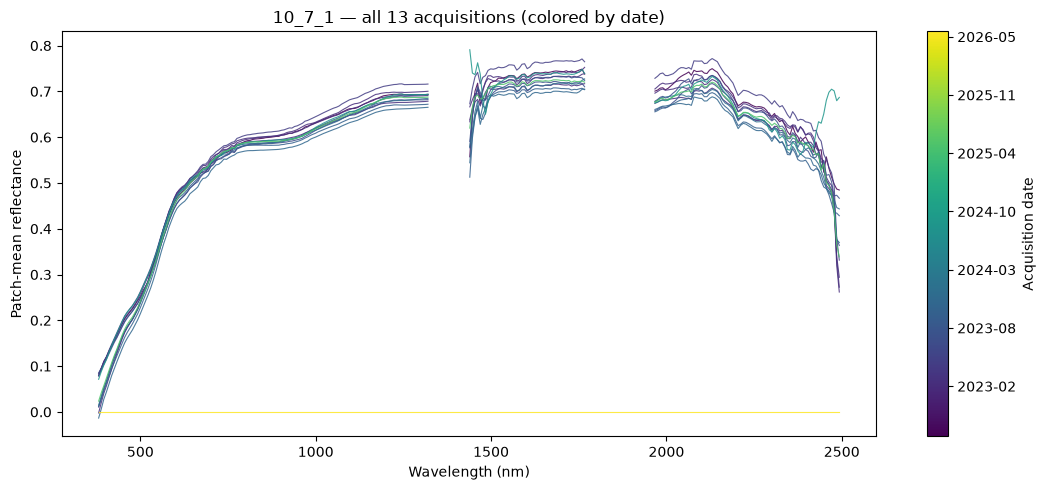

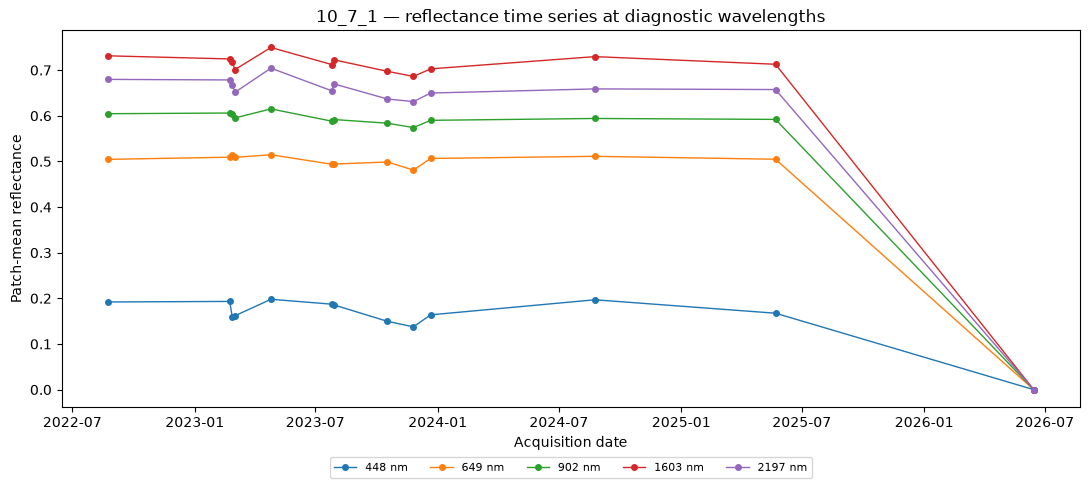

In [18]:
import re
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize

# ============================================================
# CONFIG
# ============================================================
TS_PATCH_ID = "10_7_1"
TS_PRODUCT  = "L2A_RFL"

def stamp_to_dt(ur):
    m = re.search(r"_(\d{8}T\d{6})_", ur)
    return datetime.strptime(m.group(1), "%Y%m%dT%H%M%S") if m else None

# ============================================================
# Extract patch-mean spectrum for EVERY covering granule
# ============================================================
patch_4326 = get_patch_4326(patches_gdf, TS_PATCH_ID)
covering = covering_granules(patch_4326, EMIT_PRODUCTS[TS_PRODUCT], (DATE_START, DATE_END))
print(f"{TS_PATCH_ID}: {len(covering)} covering granule(s)")

records = []
for g in covering:
    ur = g["umm"]["GranuleUR"]
    dt = stamp_to_dt(ur)
    try:
        emit = open_emit_l2a(g)
        mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
        mean_spec, _, n_pix = extract_patch(emit["reflectance"], mask)
    except Exception as ex:
        print(f"  skip {ur}: {type(ex).__name__}: {ex}")
        continue
    if mean_spec is None or n_pix == 0:
        print(f"  skip {ur}: no in-patch pixels")
        continue
    records.append({"ur": ur, "dt": dt, "n": n_pix,
                    "mean_spec": mean_spec, "wl": emit["wavelengths"]})
    print(f"  {dt:%Y-%m-%d}  n={n_pix}")

records.sort(key=lambda r: r["dt"])
if not records:
    raise RuntimeError("No acquisitions extracted.")

wl = records[0]["wl"]
mean_matrix = np.vstack([r["mean_spec"] for r in records])   # (n_acq, n_bands)
times = [r["dt"] for r in records]

# ============================================================
# FIGURE 1 — all patch-mean spectra, colored by acquisition date
# ============================================================
fig, ax = plt.subplots(figsize=(11, 5))
tnum = mdates.date2num(times)
norm = Normalize(vmin=min(tnum), vmax=max(tnum))
cmap = cm.viridis

for r, t in zip(records, tnum):
    spec = np.where(np.isfinite(r["mean_spec"]), r["mean_spec"], np.nan)
    ax.plot(wl, spec, lw=0.8, color=cmap(norm(t)), alpha=0.85)

ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Patch-mean reflectance")
ax.set_title(f"{TS_PATCH_ID} — all {len(records)} acquisitions (colored by date)")
sm = cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
cbar.set_label("Acquisition date")
plt.tight_layout(); plt.show()

# ============================================================
# FIGURE 2 — mean reflectance vs time at diagnostic wavelengths
# ============================================================
diag_nm = [450, 650, 900, 1600, 2200]   # blue, red, NIR, SWIR1, SWIR2
fig, ax = plt.subplots(figsize=(11, 5))
for target in diag_nm:
    bidx = nearest_band(wl, target)
    ax.plot(times, mean_matrix[:, bidx], marker="o", ms=4, lw=1,
            label=f"{wl[bidx]:.0f} nm")
ax.set_xlabel("Acquisition date"); ax.set_ylabel("Patch-mean reflectance")
ax.set_title(f"{TS_PATCH_ID} — reflectance time series at diagnostic wavelengths")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

No cache found — streaming VZA per granule (one-time cost).
78 bbox hits -> 78 truly intersect the PICS polygon


C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

  vza_idx resolved to 2


... (387 outputs left out)

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

An exception occurred while trying to access remote files via HTTPS
Traceback (most recent call last):
  File "C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\fsspec\implementations\http.py", line 447, in _info
    await _file_info(
    ...<5 lines>...
    )
  File "C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\fsspec\implementations\http.py", line 865, in _file_info
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\aiohttp\client_reqrep.py", line 655, in raise_for_status
    raise ClientResponseError(
    ...<5 lines>...
    )
aiohttp.client_exceptions.ClientResponseError: 502, message='Bad Gateway', url='https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/EMITL1BRAD.001/EMIT_L1B_RAD_001_20260614T120829_2616508_018/EMIT_L1B_RAD_001_20260614T120829_2616508_018.nc'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\h

  [78/78] skip EMIT_L1B_RAD_001_20260614T120829_2616508_018: FileNotFoundError: https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/EMITL1BRAD.001/EMIT_L1B_RAD_001_20260614T120829_2616508_018/EMIT_L1B_RAD_001_20260614T120829_2616508_018.nc

Cached 76 granule stats -> C:\Users\huckr\Desktop\JPL\Data\ROIs\vza_scene_stats_Libya_4.csv

76 granules in dataset.


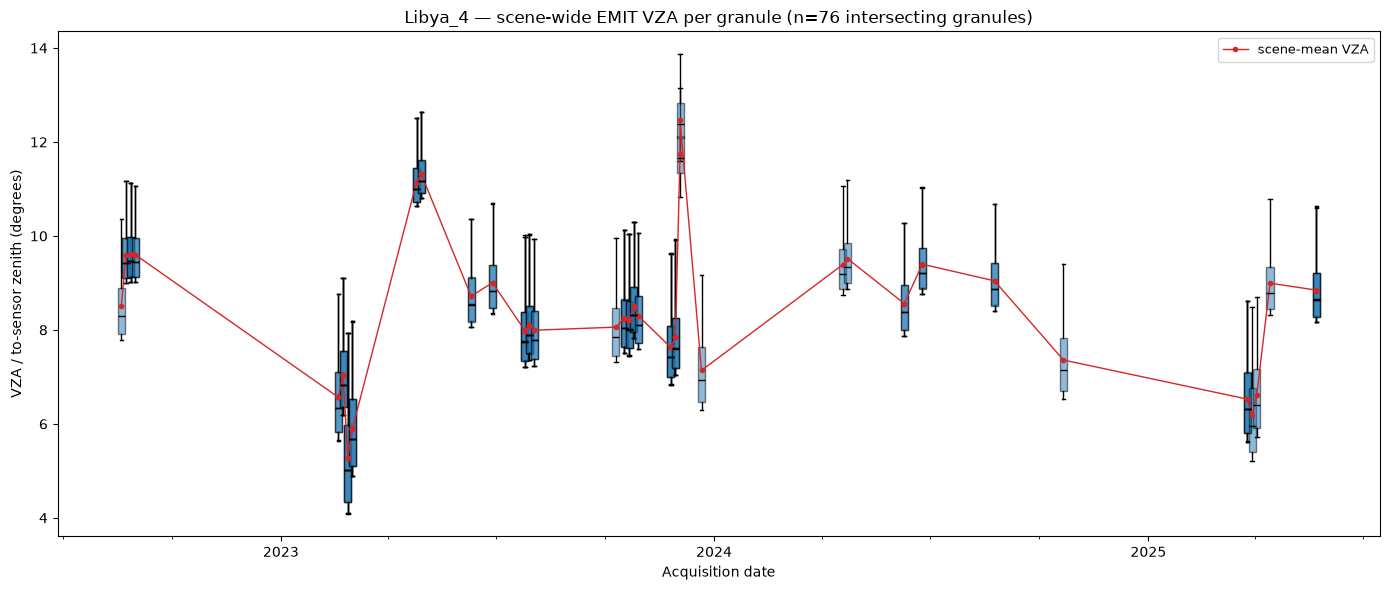

In [19]:
import os
import re
import warnings
from datetime import datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import xarray as xr
import earthaccess
import logging
logging.getLogger("fsspec").setLevel(logging.WARNING)
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ============================================================
# CONFIG
# ============================================================
PICS_NAME   = "Libya_4"
DATE_START  = "2022-08-01"
DATE_END    = "2026-06-18"
X_AXIS      = "date"          # "date" (true positions) or "index" (evenly spaced)
MAX_GRANULES = None           # set an int for a quick test run; None = all
FILL = -9999.0

PICS_GPKG = r"C:\Users\huckr\Desktop\JPL\Data\ROIs\northafrican_pics.gpkg"
CACHE_CSV = rf"C:\Users\huckr\Desktop\JPL\Data\ROIs\vza_scene_stats_{PICS_NAME}.csv"

OBS_VZA_LABEL = "To-sensor zenith (0 to 90 degrees from zenith)"

earthaccess.login(persist=True)


# ============================================================
# FUNCTIONS
# ============================================================
def granule_footprint(umm):
    gp = umm["SpatialExtent"]["HorizontalSpatialDomain"]["Geometry"]["GPolygons"]
    pts = gp[0]["Boundary"]["Points"]
    return shapely.geometry.Polygon([(p["Longitude"], p["Latitude"]) for p in pts])


def stamp_to_dt(ur):
    m = re.search(r"_(\d{8}T\d{6})_", ur)
    return datetime.strptime(m.group(1), "%Y%m%dT%H%M%S") if m else None


def open_obs(granule):
    """Return (obs_root, obs_fobj) for the OBS file in an L1B granule."""
    fobjs = earthaccess.open([granule])
    obs_fo = next(fo for fo in fobjs
                  if "OBS" in str(getattr(fo, "path", fo)).upper())
    return xr.open_dataset(obs_fo, engine="h5netcdf"), obs_fo


def vza_index(obs_fo):
    bp = xr.open_dataset(obs_fo, group="sensor_band_parameters", engine="h5netcdf")
    labels = [str(x) for x in bp["observation_bands"].values]
    return labels.index(OBS_VZA_LABEL)


def scene_vza_stats(granule, vza_idx):
    """Pull ONLY the VZA band for the whole scene; return summary stats dict."""
    obs_root, _ = open_obs(granule)
    vza = obs_root["obs"][:, :, vza_idx].values.astype("float64")
    vza[np.isclose(vza, FILL)] = np.nan
    v = vza[np.isfinite(vza)]
    if v.size == 0:
        return None
    return {
        "min": np.min(v), "max": np.max(v),
        "mean": np.mean(v), "std": np.std(v),
        "p25": np.percentile(v, 25), "p50": np.percentile(v, 50),
        "p75": np.percentile(v, 75),
    }


# ============================================================
# BUILD OR LOAD CACHE
# ============================================================
if os.path.exists(CACHE_CSV):
    print(f"Loading cached stats: {CACHE_CSV}")
    df = pd.read_csv(CACHE_CSV, parse_dates=["datetime"])
else:
    print("No cache found — streaming VZA per granule (one-time cost).")

    # PICS polygon in 4326 for the exact intersect test
    pics_gdf = gpd.read_file(PICS_GPKG)
    pics_poly = gpd.GeoSeries(
        [pics_gdf[pics_gdf["site_name"] == PICS_NAME.replace("_", " ")].geometry.iloc[0]],
        crs=pics_gdf.crs).to_crs(4326).iloc[0]
    w, s, e, n = pics_poly.bounds

    # CMR bbox search, then exact polygon-intersect filter
    results = earthaccess.search_data(
        short_name="EMITL1BRAD", bounding_box=(w, s, e, n),
        temporal=(DATE_START, DATE_END), count=-1)
    intersecting = [g for g in results
                    if granule_footprint(g["umm"]).intersects(pics_poly)]
    print(f"{len(results)} bbox hits -> {len(intersecting)} truly intersect the PICS polygon")

    if MAX_GRANULES:
        intersecting = intersecting[:MAX_GRANULES]
        print(f"  (capped to first {MAX_GRANULES} for test run)")

    vza_idx = None
    rows = []
    for i, g in enumerate(intersecting):
        ur = g["umm"]["GranuleUR"]
        try:
            if vza_idx is None:                       # look up ONCE, then reuse
                _, obs_fo = open_obs(g)
                vza_idx = vza_index(obs_fo)
                print(f"  vza_idx resolved to {vza_idx}")
            st = scene_vza_stats(g, vza_idx)
        except Exception as ex:
            print(f"  [{i+1}/{len(intersecting)}] skip {ur}: {type(ex).__name__}: {ex}")
            continue
        if st is None:
            continue
        st.update({"granule_ur": ur, "datetime": stamp_to_dt(ur)})
        rows.append(st)
        print(f"  [{i+1}/{len(intersecting)}] {st['datetime']:%Y-%m-%d}  "
              f"VZA mean={st['mean']:.1f}  [{st['min']:.1f}, {st['max']:.1f}]")

    df = pd.DataFrame(rows).sort_values("datetime").reset_index(drop=True)
    df.to_csv(CACHE_CSV, index=False)
    print(f"\nCached {len(df)} granule stats -> {CACHE_CSV}")

print(f"\n{len(df)} granules in dataset.")


# ============================================================
# PLOT — box-and-whisker per granule over time
# ============================================================
df = df.sort_values("datetime").reset_index(drop=True)

if X_AXIS == "date":
    positions = mdates.date2num(df["datetime"])
    box_width = 6          # days
else:  # index
    positions = np.arange(len(df))
    box_width = 0.6

# Build boxplot inputs from cached percentiles (no need to re-stream pixels).
bxp_stats = [{
    "med": r["p50"], "q1": r["p25"], "q3": r["p75"],
    "whislo": r["min"], "whishi": r["max"], "fliers": [],
    "label": "",
} for _, r in df.iterrows()]

fig, ax = plt.subplots(figsize=(14, 6))
ax.bxp(bxp_stats, positions=positions, widths=box_width,
       showfliers=False, patch_artist=True,
       boxprops=dict(facecolor="C0", alpha=0.5),
       medianprops=dict(color="black"))

# overlay mean as a connecting line so the trend reads through crowded boxes
ax.plot(positions, df["mean"], color="C3", lw=1, marker="o", ms=3,
        label="scene-mean VZA")

ax.set_ylabel("VZA / to-sensor zenith (degrees)")
ax.set_title(f"{PICS_NAME} — scene-wide EMIT VZA per granule "
             f"(n={len(df)} intersecting granules)")
ax.legend(fontsize=9)

if X_AXIS == "date":
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.set_xlabel("Acquisition date")
else:
    ax.set_xlabel("Acquisition index (chronological)")

plt.tight_layout(); plt.show()

## Wrapper that pulls spectra and plots RGB for all scenes covering a patch

In [17]:
import pandas as pd
from datetime import datetime

# ============================================================
# CONFIG
# ============================================================
TS_PATCH_ID  = "10_7_1"      # patch to extract the full time series for
TS_PRODUCT   = "L2A_RFL"
RGB_VMIN, RGB_VMAX = 0.0, 0.45   # fixed stretch, shared across all scenes


def acquisition_time_from_ur(ur):
    """Parse acquisition datetime from an EMIT granule UR
    (…_YYYYMMDDTHHMMSS_…)."""
    import re
    m = re.search(r"_(\d{8}T\d{6})_", ur)
    return datetime.strptime(m.group(1), "%Y%m%dT%H%M%S") if m else None


def extract_patch_timeseries(patch_id, product, date_range=None):
    """Run the single-granule extraction over EVERY granule that fully covers
    the patch. Returns a dict of per-acquisition results, sorted by time."""
    patch_4326 = get_patch_4326(patch_id)

    urs = patch_granules[patch_id][product]
    if not urs:
        raise ValueError(f"No fully-covering {product} granules for {patch_id}.")

    # Cache ALL granule objects for this patch in ONE search (not per-UR).
    if date_range is None:
        date_range = (DATE_START_ALL, DATE_END_ALL)
    all_g = earthaccess.search_data(
        short_name=EMIT_PRODUCTS[product],
        bounding_box=tuple(patch_4326.bounds),
        temporal=date_range,
        count=-1,
    )
    g_by_ur = {g["umm"].get("GranuleUR"): g for g in all_g}

    records = []
    for ur in urs:
        granule = g_by_ur.get(ur)
        if granule is None:
            print(f"  skip {ur}: object not found in search cache")
            continue
        try:
            emit = open_emit_l2a(granule)
            mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
            mean_spec, pix_stack, n_pix = extract_patch(emit["reflectance"], mask)
        except Exception as ex:
            print(f"  skip {ur}: {type(ex).__name__}: {ex}")
            continue
        if mean_spec is None or n_pix == 0:
            print(f"  skip {ur}: no in-patch pixels")
            continue

        records.append({
            "ur": ur,
            "datetime": acquisition_time_from_ur(ur),
            "n_pixels": n_pix,
            "mean_spec": mean_spec,
            "std_spec": np.nanstd(pix_stack, axis=0),
            "wavelengths": emit["wavelengths"],
        })
        print(f"  {ur}  n={n_pix}")

    records.sort(key=lambda r: r["datetime"] or datetime.min)
    print(f"\n{patch_id}: extracted {len(records)} acquisition(s).")
    return records, g_by_ur


# ============================================================
# RUN
# ============================================================
ts, g_by_ur = extract_patch_timeseries(TS_PATCH_ID, TS_PRODUCT)

if not ts:
    raise RuntimeError("No acquisitions extracted.")

wl = ts[0]["wavelengths"]
mean_matrix = np.vstack([r["mean_spec"] for r in ts])   # (n_acq, n_bands)
times = [r["datetime"] for r in ts]

# ============================================================
# FIGURE 1 — all mean spectra, colored by acquisition date
# ============================================================
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(11, 5))
tnum = mdates.date2num(times)
norm = Normalize(vmin=min(tnum), vmax=max(tnum))
cmap = cm.viridis

for r, t in zip(ts, tnum):
    plot_spec = np.where(np.isfinite(r["mean_spec"]), r["mean_spec"], np.nan)
    ax.plot(wl, plot_spec, lw=0.8, color=cmap(norm(t)), alpha=0.8)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title(f"{TS_PATCH_ID} — patch-mean spectra, all {len(ts)} acquisitions")
sm = cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
cbar.set_label("Acquisition date")
plt.tight_layout(); plt.show()

# ============================================================
# FIGURE 2 — per-band reflectance vs time at a few diagnostic wavelengths
# ============================================================
diag_nm = [450, 650, 900, 1600, 2200]   # blue, red, NIR, SWIR1, SWIR2
fig, ax = plt.subplots(figsize=(11, 5))
for target in diag_nm:
    bidx = nearest_band(wl, target)
    series = mean_matrix[:, bidx]
    ax.plot(times, series, marker="o", ms=4, lw=1, label=f"{wl[bidx]:.0f} nm")
ax.set_xlabel("Acquisition date")
ax.set_ylabel("Patch-mean reflectance")
ax.set_title(f"{TS_PATCH_ID} — reflectance time series at diagnostic wavelengths")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

# ============================================================
# FIGURE 3 — RGB contact sheet, one panel per acquisition (shared fixed stretch)
# ============================================================
import math
n = len(ts)
ncols = min(5, n)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False)
axes = axes.ravel()
patch_4326 = get_patch_4326(TS_PATCH_ID)

for ax, r in zip(axes, ts):
    g = g_by_ur[r["ur"]]                       # reuse the cached granule object
    emit = open_emit_l2a(g)
    mask = patch_pixel_mask(patch_4326, emit["lon"], emit["lat"])
    rgba, _ = patch_rgb(emit["reflectance"], mask, emit["wavelengths"],
                        vmin=RGB_VMIN, vmax=RGB_VMAX)
    if rgba is not None:
        ax.imshow(rgba, interpolation="nearest")
    ax.set_title(f"{r['datetime']:%Y-%m-%d}\nn={r['n_pixels']}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes[n:]:
    ax.axis("off")
fig.suptitle(f"{TS_PATCH_ID} — true-color RGB per acquisition (fixed stretch)",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

TypeError: get_patch_4326() missing 1 required positional argument: 'patch_id'

In [16]:
# ============================================================
# CONFIG  (assumes patches_gdf, patch_granules, PICS_NAME,
#          EMIT_PRODUCTS, DATE_START_ALL/END_ALL, patch_pixel_mask,
#          get_patch_4326, nearest_band exist from the RFL script)
# ============================================================
EXTRACT_PATCH_ID = "10_7_1"      # patch to extract; must exist in patches_gdf
RAD_PRODUCT      = "L1B_RAD"
FILL = -9999.0


def open_emit_l1b(granule):
    """Open an EMIT L1B RAD granule via earthaccess (authenticated streaming),
    reading groups by name. Returns a dict:
        lon, lat   : (downtrack, crosstrack)
        radiance   : (downtrack, crosstrack, bands)  lazy DataArray
        wavelengths, fwhm : (bands,)
    `granule` is an earthaccess DataGranule, NOT a URL string.
    """
    fobj = earthaccess.open([granule])[0]

    root = xr.open_dataset(fobj, engine="h5netcdf")
    rad = root["radiance"]                            # ('downtrack','crosstrack','bands')

    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    wavelengths = np.asarray(bp["wavelengths"].data, dtype="float64")
    fwhm = np.asarray(bp["fwhm"].data, dtype="float64") if "fwhm" in bp else None

    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    lon = np.asarray(loc["lon"].data, dtype="float64")
    lat = np.asarray(loc["lat"].data, dtype="float64")

    return {"root": root, "radiance": rad, "wavelengths": wavelengths,
            "fwhm": fwhm, "lon": lon, "lat": lat}


def extract_patch_rad(rad, mask, fill_values=(-9999.0,)):
    """Stream only the masked block. Return (mean_spectrum, pixel_stack, n_pixels).
    L1B radiance: only -9999 no-data fill is masked (no -0.01 absorption flag)."""
    if not mask.any():
        return None, None, 0
    rows, cols = np.where(mask)
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    block = rad[r0:r1, c0:c1, :].values
    submask = mask[r0:r1, c0:c1]
    pix = block[submask, :].astype("float64")
    for fv in fill_values:
        pix[np.isclose(pix, fv)] = np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_spec = np.nanmean(pix, axis=0)
    return mean_spec, pix, pix.shape[0]


# ============================================================
# DRIVER — one granule, validate the mechanic
# ============================================================
patch_4326 = get_patch_4326(EXTRACT_PATCH_ID)

urs = patch_granules[EXTRACT_PATCH_ID][RAD_PRODUCT]
if not urs:
    raise ValueError(f"No fully-covering {RAD_PRODUCT} granules for {EXTRACT_PATCH_ID}.")
target_ur = urs[0]

match = [g for g in earthaccess.search_data(
            short_name=EMIT_PRODUCTS[RAD_PRODUCT],
            temporal=(DATE_START_ALL, DATE_END_ALL),
            bounding_box=tuple(patch_4326.bounds),
            count=-1)
         if g["umm"].get("GranuleUR") == target_ur]
if not match:
    raise RuntimeError(f"Could not resolve granule for {target_ur}")
granule = match[0]
print(f"Patch {EXTRACT_PATCH_ID} | granule {target_ur}")

emit = open_emit_l1b(granule)
lon, lat = emit["lon"], emit["lat"]
rad, wl = emit["radiance"], emit["wavelengths"]
print("radiance dims/shape:", rad.dims, rad.shape)

mask = patch_pixel_mask(patch_4326, lon, lat)
mean_spec, pix_stack, n_pix = extract_patch_rad(rad, mask)

patch_km = int(EXTRACT_PATCH_ID.split("_")[0])
theoretical = (patch_km * 1000 / 60) ** 2
print(f"In-patch pixels: {n_pix}  (theoretical full {patch_km} km @60m ~= {theoretical:,.0f})")

# ============================================================
# QUICK VALIDATION PLOT — radiance spectrum
# ============================================================
if mean_spec is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    sd = np.nanstd(pix_stack, axis=0)
    ax.plot(wl, mean_spec, lw=1, color="C3")
    ax.fill_between(wl, mean_spec - sd, mean_spec + sd, color="C3", alpha=0.2)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Radiance (W cm⁻² nm⁻¹ sr⁻¹)")   # confirm units from file attrs
    ax.set_title(f"{EXTRACT_PATCH_ID} mean radiance (n={n_pix} px, ±1σ)")
    plt.tight_layout(); plt.show()
else:
    print("No pixels fell inside the patch — check CRS/containment.")

TypeError: get_patch_4326() missing 1 required positional argument: 'patch_id'

In [17]:
fobj = earthaccess.open([granule])[0]
root = xr.open_dataset(fobj, engine="h5netcdf")

print("=== ROOT GROUP ===")
print("data_vars:", list(root.data_vars))
print("dims:", dict(root.sizes))
print("coords:", list(root.coords))

# 1. Is there a variable literally named 'radiance' in root?
has_radiance = "radiance" in root.data_vars
print(f"\n'radiance' in root data_vars? {has_radiance}")

if has_radiance:
    rad = root["radiance"]
    print(f"  dims:  {rad.dims}")
    print(f"  shape: {rad.shape}")

    # 2. Dims match the expected (downtrack, crosstrack, bands)?
    expected = ("downtrack", "crosstrack", "bands")
    print(f"\n  dims == {expected}? {rad.dims == expected}")
    if rad.dims != expected:
        print("  !! dim names/order differ -- adjust indexing accordingly")

    # 3. Cross-check the band axis length against the wavelength count
    bp = xr.open_dataset(fobj, group="sensor_band_parameters", engine="h5netcdf")
    n_wl = bp["wavelengths"].size
    band_len = rad.sizes.get("bands", None)
    print(f"\n  bands dim length: {band_len}")
    print(f"  wavelengths length: {n_wl}")
    print(f"  match? {band_len == n_wl}")

    # 4. Confirm the two spatial dims match the geolocation arrays
    loc = xr.open_dataset(fobj, group="location", engine="h5netcdf")
    print(f"\n  lon shape: {loc['lon'].shape}")
    print(f"  radiance spatial dims: ({rad.sizes.get('downtrack')}, {rad.sizes.get('crosstrack')})")
else:
    print("  Available data_vars instead:", list(root.data_vars))
    print("  -> the radiance variable is named something else; use that name.")

C:\Users\huckr\miniconda3\envs\emit-pics\Lib\site-packages\earthaccess\store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)
2026-06-23 15:30:59,659  INFO      earthaccess.store  Opening 1 granules, approx size: 1.83 GB


QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

=== ROOT GROUP ===
data_vars: ['radiance']
dims: {'downtrack': 1280, 'crosstrack': 1242, 'bands': 285}
coords: []

'radiance' in root data_vars? True
  dims:  ('downtrack', 'crosstrack', 'bands')
  shape: (1280, 1242, 285)

  dims == ('downtrack', 'crosstrack', 'bands')? True

  bands dim length: 285
  wavelengths length: 285
  match? True

  lon shape: (1280, 1242)
  radiance spatial dims: (1280, 1242)


In [18]:
import geopandas as gpd
from pathlib import Path

# ---- config ----
EXPORT_PATCH_ID = "10_7_1"
OUT_DIR = r"C:\Users\huckr\Desktop\JPL\Data\ROIs\patch_shp_for_AppEEARS"
# ----------------

sub = patches_gdf[patches_gdf["patch_id"] == EXPORT_PATCH_ID].copy()
if sub.empty:
    raise ValueError(f"patch_id '{EXPORT_PATCH_ID}' not in patches_gdf.")

# Reproject UTM -> EPSG:4326 for AppEEARS (it expects geographic coords).
sub_4326 = sub.to_crs("EPSG:4326")

# Keep attributes short: shapefile DBF truncates field names to 10 chars.
keep = [c for c in ["patch_id", "size_km", "row", "col"] if c in sub_4326.columns]
sub_4326 = sub_4326[keep + ["geometry"]]

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
out_path = str(Path(OUT_DIR) / f"patch_{EXPORT_PATCH_ID}.shp")
sub_4326.to_file(out_path, driver="ESRI Shapefile")

print(f"Wrote {out_path}")
print(f"CRS: {sub_4326.crs}")
print(f"Bounds (lon/lat): {sub_4326.total_bounds}")
print("Sidecar files (.shp/.shx/.dbf/.prj) written alongside.")

2026-06-23 16:04:21,327  INFO      pyogrio._io  Created 1 records


Wrote C:\Users\huckr\Desktop\JPL\Data\ROIs\patch_shp_for_AppEEARS\patch_10_7_1.shp
CRS: EPSG:4326
Bounds (lon/lat): [23.07827105 28.28298973 23.18201721 28.37478786]
Sidecar files (.shp/.shx/.dbf/.prj) written alongside.
